# Milestone 2: Conditional generation, guidance and noise schedule tuning
**From Words to Worlds: Text-to-Image Generation**, IE 7615

| Task | Section |
|---|---|
| Connect the text encoder to the diffusion model | 1 |
| Baseline conditional generation | 2 |
| Tune classifier free guidance and the noise schedule | 3 |
| First set of generated images | 4 |

Every generated image is logged in `results/logs/generation_log.csv`. The sweep images are saved to Drive (`MyDrive/t2i/m2_sweeps/`), and the samples, grids, plots and metrics are saved to `results/`. The whole notebook takes about 40 minutes on a Colab T4 GPU.

## 0. Setup

In [1]:
import os, sys
from google.colab import drive
drive.mount("/content/drive")

REPO_URL = "https://github.com/Aryan16d/IE7615-Generative-milestone.git"
REPO_DIR = "/content/IE7615-Generative-milestone"
if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull -q
else:
    !git clone -q {REPO_URL} {REPO_DIR}
%pip install -q -r {REPO_DIR}/requirements.txt
sys.path.insert(0, REPO_DIR)

Mounted at /content/drive


In [2]:
import inspect, json, shutil, textwrap, time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from IPython.display import Image as IPImage, display
from transformers import CLIPModel, CLIPProcessor
from diffusers import (StableDiffusionPipeline, PNDMScheduler, DDIMScheduler, DDPMScheduler,
                       EulerDiscreteScheduler, EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler)

SEED = 39
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE, DTYPE = "cuda", torch.float16
H = W = 512
SD_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
CLIP_ID = "openai/clip-vit-large-patch14"

DRIVE_ROOT  = Path("/content/drive/MyDrive/t2i")
PROC_DIR    = DRIVE_ROOT / "data" / "processed"
SWEEP_DIR   = DRIVE_ROOT / "m2_sweeps"
REPO_DIR    = Path(REPO_DIR)
RESULTS_DIR = REPO_DIR / "results"
SAMPLES_DIR = RESULTS_DIR / "samples" / "m2_tuning"
METRICS_DIR = RESULTS_DIR / "metrics"
PLOTS_DIR   = RESULTS_DIR / "plots"
LOG_CSV     = RESULTS_DIR / "logs" / "generation_log.csv"
for d in (SAMPLES_DIR, METRICS_DIR, PLOTS_DIR, SWEEP_DIR):
    d.mkdir(parents=True, exist_ok=True)

prompts = [l.strip() for l in open(REPO_DIR / "prompts" / "test_prompts.txt") if l.strip()]
print(f"{len(prompts)} test prompts | device {DEVICE} | torch {torch.__version__}")
for i, p in enumerate(prompts, 1):
    print(f"  {i}. {p}")

5 test prompts | device cuda | torch 2.14.1+cu130
  1. a red double-decker bus driving down a busy city street
  2. two cats sleeping on a blue couch next to a remote control
  3. a plate with a slice of pizza on the left and a fork on the right
  4. a man riding a surfboard on a large wave at sunset
  5. a bowl of oranges and bananas on a wooden kitchen table


## 0.1 Helper functions
These are the functions used by every section below: the diffusion loop, the samplers, CLIPScore, logging and image grids.

In [3]:
SCHEDULERS = {
    "PNDM (SD default)": lambda c: PNDMScheduler.from_config(c),
    "DDIM":              lambda c: DDIMScheduler.from_config(c),
    "DDPM":              lambda c: DDPMScheduler.from_config(c),
    "Euler":             lambda c: EulerDiscreteScheduler.from_config(c),
    "Euler (Karras)":    lambda c: EulerDiscreteScheduler.from_config(c, use_karras_sigmas=True),
    "Euler a":           lambda c: EulerAncestralDiscreteScheduler.from_config(c),
    "DPM++ 2M":          lambda c: DPMSolverMultistepScheduler.from_config(c, algorithm_type="dpmsolver++"),
    "DPM++ 2M Karras":   lambda c: DPMSolverMultistepScheduler.from_config(c, algorithm_type="dpmsolver++",
                                                                          use_karras_sigmas=True),
}


@torch.no_grad()
def encode_text(texts):
    ids = tokenizer(texts, padding="max_length", max_length=77, truncation=True,
                    return_tensors="pt").input_ids.to(DEVICE)
    return text_encoder(input_ids=ids).last_hidden_state


@torch.no_grad()
def denoise(scheduler, cond, uncond, guidance, steps, seed):
    scheduler.set_timesteps(steps, device=DEVICE)
    shape = (1, unet.config.in_channels, H // 8, W // 8)
    noise = torch.randn(shape, generator=torch.Generator(DEVICE).manual_seed(seed), device=DEVICE, dtype=cond.dtype)
    latents = noise.repeat(len(cond), 1, 1, 1) * scheduler.init_noise_sigma

    do_cfg = guidance > 1
    emb = torch.cat([uncond, cond]) if do_cfg else cond
    kw = {}
    if "generator" in inspect.signature(scheduler.step).parameters:
        kw["generator"] = torch.Generator(DEVICE).manual_seed(seed)

    for t in scheduler.timesteps:
        x = torch.cat([latents] * 2) if do_cfg else latents
        eps = unet(scheduler.scale_model_input(x, t), t, encoder_hidden_states=emb).sample
        if do_cfg:
            eps_u, eps_c = eps.chunk(2)
            eps = eps_u + guidance * (eps_c - eps_u)
        latents = scheduler.step(eps, t, latents, **kw).prev_sample
    return latents


@torch.no_grad()
def decode(latents):
    img = vae.decode(latents / vae.config.scaling_factor).sample
    img = (img / 2 + 0.5).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()
    return [Image.fromarray((x * 255).round().astype("uint8")) for x in img]


def nsfw_flags(images):
    px = pipe.feature_extractor(images, return_tensors="pt").pixel_values.to(DEVICE, DTYPE)
    arr = np.stack([np.asarray(i, dtype=np.float32) / 255 for i in images])
    _, flags = pipe.safety_checker(images=arr, clip_input=px)
    return [bool(f) for f in flags]


def generate(cond, uncond, seed, scheduler, steps, guidance):
    sched = SCHEDULERS[scheduler](pipe.scheduler.config)
    torch.cuda.synchronize(); t0 = time.time()
    imgs = decode(denoise(sched, cond, uncond.expand(len(cond), -1, -1), guidance, steps, seed))
    torch.cuda.synchronize(); dt = (time.time() - t0) / len(cond)
    flags = nsfw_flags(imgs)
    imgs = [Image.new("RGB", im.size) if f else im for im, f in zip(imgs, flags)]
    return imgs, dt, flags


@torch.no_grad()
def clip_score(images, texts):
    images = [Image.open(i).convert("RGB") if isinstance(i, (str, Path)) else i for i in images]
    px = clip_proc(images=images, return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
    tok = clip_proc(text=list(texts), padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEVICE)
    img = clip_model.visual_projection(clip_model.vision_model(pixel_values=px).pooler_output)
    txt = clip_model.text_projection(clip_model.text_model(input_ids=tok["input_ids"],
                                                           attention_mask=tok["attention_mask"]).pooler_output)
    img = (img / img.norm(dim=-1, keepdim=True)).float()
    txt = (txt / txt.norm(dim=-1, keepdim=True)).float()
    return [round(float(x), 2) for x in (img * txt).sum(-1).clamp(min=0).cpu() * 100]


def mean_saturation(img):
    return round(float(np.asarray(img.convert("HSV"))[..., 1].mean() / 255), 4)


metrics = []
STAMP = datetime.now().strftime("%Y%m%d-%H%M%S")


def rel(path):
    return str(path.relative_to(REPO_DIR)) if path.is_relative_to(REPO_DIR) else str(path)


def record(images, texts, seed, out_dir, experiment, scheduler, steps, guidance, runtime_s, flags,
           ext="jpg", tag="", notes=""):
    out_dir.mkdir(parents=True, exist_ok=True)
    scores = [float("nan") if f else s for s, f in zip(clip_score(images, texts), flags)]
    log_rows = []
    for k, (img, text, score, flag) in enumerate(zip(images, texts, scores, flags), 1):
        pid = prompts.index(text) + 1 if text in prompts else k
        path = out_dir / f"{tag}p{pid:02d}_s{seed}.{ext}"
        img.save(path, quality=92)
        note = "; ".join(n for n in [notes, "safety checker flagged (black image)" if flag else ""] if n)
        log_rows.append(dict(run_id=f"m2-{STAMP}-{len(metrics) + 1:03d}",
                             timestamp=datetime.now().isoformat(timespec="seconds"), milestone="M2",
                             prompt=text, seed=seed, model_id=SD_ID, scheduler=scheduler, num_steps=steps,
                             guidance_scale=guidance, height=H, width=W, output_path=rel(path),
                             runtime_s=round(runtime_s, 2), notes=note))
        metrics.append(dict(experiment=experiment, prompt_id=pid, prompt=text, seed=seed, scheduler=scheduler,
                            steps=steps, guidance=guidance, clip_score=score,
                            saturation=float("nan") if flag else mean_saturation(img),
                            runtime_s=round(runtime_s, 2), flagged=flag, path=rel(path)))
    pd.DataFrame(log_rows).to_csv(LOG_CSV, mode="a", index=False, header=not LOG_CSV.exists())
    return scores


def save_grid(images, path, row_labels=None, col_labels=None, cell=3.0, title=None, wrap=28):
    R, C = len(images), max(len(r) for r in images)
    fig, ax = plt.subplots(R, C, figsize=(cell * C, cell * R + (0.4 if title else 0)), squeeze=False)
    for i in range(R):
        for j in range(C):
            a = ax[i, j]
            a.set_xticks([]); a.set_yticks([])
            for s in a.spines.values():
                s.set_visible(False)
            if j < len(images[i]):
                a.imshow(images[i][j])
            if i == 0 and col_labels:
                a.set_title(textwrap.fill(str(col_labels[j]), wrap), fontsize=9)
            if j == 0 and row_labels:
                a.set_ylabel(textwrap.fill(str(row_labels[i]), wrap), fontsize=8)
    if title:
        fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.savefig(path, dpi=70, pil_kwargs={"quality": 85}); plt.close(fig)
    return path


def show(path, width=1000):
    display(IPImage(filename=str(path), width=width))

## 1. Connecting the text encoder to the diffusion model
Stable Diffusion is a latent diffusion model. In Milestone 1 we simply called `pipe(prompt)`. Here we connect each part ourselves:

```
prompt ──tokenizer──► 77 token ids ──CLIP text encoder──► c ∈ R^{77×768}
                                                             │ (cross-attention)
z_T ~ N(0, I) ∈ R^{4×64×64} ──► UNet ε_θ(z_t, t, c) ──scheduler step──► z_{t-1} … ► z_0 ──VAE decoder──► 512×512 image
```

**Classifier free guidance.** At every step, the UNet runs twice: once with the prompt embedding `c`, and once with the embedding of an empty prompt `∅`. The two predictions are then combined:

  ε̂ = ε_θ(z_t, t, ∅) + w · (ε_θ(z_t, t, c) − ε_θ(z_t, t, ∅))

With `w = 1` this is normal conditional sampling. A larger `w` makes the image follow the prompt more closely.

In [4]:
pipe = StableDiffusionPipeline.from_pretrained(SD_ID, dtype=DTYPE, variant="fp16").to(DEVICE)
pipe.set_progress_bar_config(disable=True)
tokenizer, text_encoder, unet, vae = pipe.tokenizer, pipe.text_encoder, pipe.unet, pipe.vae

clip_model = CLIPModel.from_pretrained(CLIP_ID, dtype=DTYPE).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)

n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"text encoder : {type(text_encoder).__name__:22s} {n_params(text_encoder):7.1f} M params | hidden {text_encoder.config.hidden_size}")
print(f"UNet         : {type(unet).__name__:22s} {n_params(unet):7.1f} M params | cross_attention_dim {unet.config.cross_attention_dim}")
print(f"VAE          : {type(vae).__name__:22s} {n_params(vae):7.1f} M params | latent channels {vae.config.latent_channels}, scale {vae.config.scaling_factor}")
print(f"scheduler    : {type(pipe.scheduler).__name__} | {pipe.scheduler.config.num_train_timesteps} train steps, beta schedule '{pipe.scheduler.config.beta_schedule}'")
assert unet.config.cross_attention_dim == text_encoder.config.hidden_size

text encoder : CLIPTextModel            123.1 M params | hidden 768
UNet         : UNet2DConditionModel     859.5 M params | cross_attention_dim 768
VAE          : AutoencoderKL             83.7 M params | latent channels 4, scale 0.18215
scheduler    : PNDMScheduler | 1000 train steps, beta schedule 'scaled_linear'


In [5]:
cond = encode_text(prompts)
uncond = encode_text([""])
print("cond:", tuple(cond.shape), cond.dtype, "| uncond:", tuple(uncond.shape))

gap = (cond.float() - uncond.float()).norm(dim=-1).mean(-1).cpu()
for p, g in zip(prompts, gap):
    print(f"  ||c - ∅|| = {g:5.2f}   {p}")

cond: (5, 77, 768) torch.float16 | uncond: (1, 77, 768)
  ||c - ∅|| = 35.92   a red double-decker bus driving down a busy city street
  ||c - ∅|| = 36.20   two cats sleeping on a blue couch next to a remote control
  ||c - ∅|| = 34.80   a plate with a slice of pizza on the left and a fork on the right
  ||c - ∅|| = 36.42   a man riding a surfboard on a large wave at sunset
  ||c - ∅|| = 36.17   a bowl of oranges and bananas on a wooden kitchen table


### 1.1 Sanity check: our loop matches `pipe()`
Both use the same prompt, seed 39, PNDM, 50 steps and `w = 7.5`. Any small differences come from fp16 math on the GPU.

pixel diff vs pipe(): mean 0.628, max 86 (0–255 scale)


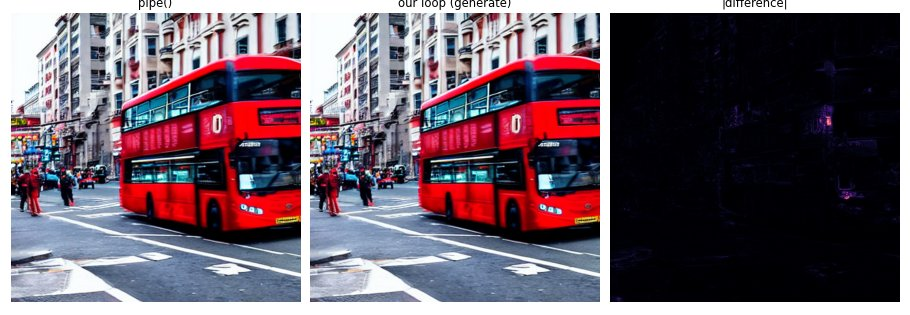

In [6]:
ref = pipe(prompts[0], num_inference_steps=50, guidance_scale=7.5,
           generator=torch.Generator(DEVICE).manual_seed(SEED)).images[0]
ours = generate(cond[:1], uncond, SEED, "PNDM (SD default)", 50, 7.5)[0][0]

diff = np.abs(np.asarray(ref, dtype=np.int16) - np.asarray(ours, dtype=np.int16))
print(f"pixel diff vs pipe(): mean {diff.mean():.3f}, max {diff.max()} (0–255 scale)")
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
for a, im, t in zip(ax, [ref, ours, diff.mean(-1)], ["pipe()", "our loop (generate)", "|difference|"]):
    a.imshow(im, cmap="magma" if t.startswith("|") else None); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "m2_sanity_check.jpg", dpi=70, pil_kwargs={"quality": 85}); plt.close(fig)
show(PLOTS_DIR / "m2_sanity_check.jpg", 900)

### 1.2 Why CLIP and not BERT?
BERT base also gives a 768 number vector for each token, so it fits the shape the UNet expects. But the UNet was only trained on CLIP embeddings, so without fine tuning, BERT gives images that ignore the prompt.

BERT embeddings: (3, 77, 768) (same shape as CLIP, different space)


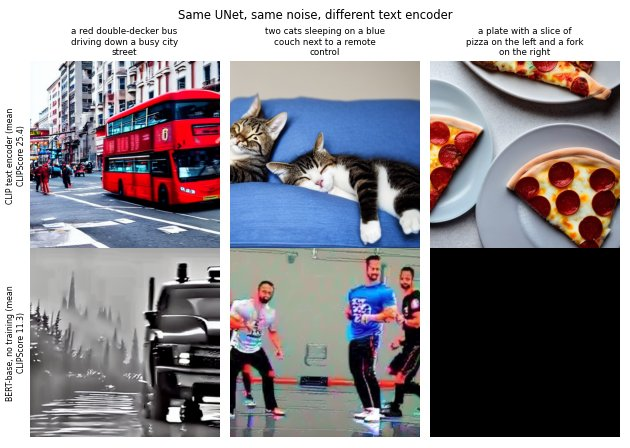

In [7]:
from transformers import BertTokenizer, BertModel
btok = BertTokenizer.from_pretrained("bert-base-uncased")
bert = BertModel.from_pretrained("bert-base-uncased", dtype=DTYPE).to(DEVICE).eval()
with torch.no_grad():
    b_cond, b_uncond = [bert(**btok(t, padding="max_length", max_length=77, truncation=True,
                                    return_tensors="pt").to(DEVICE)).last_hidden_state
                        for t in (prompts[:3], [""])]
del bert; torch.cuda.empty_cache()
print("BERT embeddings:", tuple(b_cond.shape), "(same shape as CLIP, different space)")

enc_imgs, enc_scores = {}, {}
for name, c, u in [("CLIP", cond[:3], uncond), ("BERT", b_cond, b_uncond)]:
    imgs, dt, fl = generate(c, u, SEED, "DPM++ 2M Karras", 25, 7.5)
    enc_scores[name] = record(imgs, prompts[:3], SEED, SAMPLES_DIR / "encoder_clip_vs_bert", f"encoder: {name}",
                              "DPM++ 2M Karras", 25, 7.5, dt, fl, tag=f"{name.lower()}_")
    enc_imgs[name] = imgs

g = save_grid([enc_imgs["CLIP"], enc_imgs["BERT"]], PLOTS_DIR / "m2_encoder_clip_vs_bert.jpg",
              row_labels=[f"CLIP text encoder\n(mean CLIPScore {np.nanmean(enc_scores['CLIP']):.1f})",
                          f"BERT-base, no training\n(mean CLIPScore {np.nanmean(enc_scores['BERT']):.1f})"],
              col_labels=prompts[:3], title="Same UNet, same noise, different text encoder")
show(g, 900)

## 2. Baseline conditional generation
The baseline uses the Stable Diffusion defaults (PNDM, 50 steps, `w = 7.5`) on seeds 39 to 42. These are the same seeds we use for the tuned setup in Section 4. We also generate images with an empty prompt from the same starting noise, to show that the text is what drives the image.

To measure how well an image matches its prompt, we use **CLIPScore**: 100 × the cosine similarity between the image and the prompt in CLIP space. A higher score means a better match.

In [8]:
BASE = dict(scheduler="PNDM (SD default)", steps=50, guidance=7.5)
EVAL_SEEDS = [SEED, SEED + 1, SEED + 2, SEED + 3]

for s in EVAL_SEEDS:
    imgs, dt, fl = generate(cond, uncond, s, **BASE)
    sc = record(imgs, prompts, s, SAMPLES_DIR / "baseline", "baseline (conditional)", **BASE, runtime_s=dt,
                flags=fl, ext="png" if s == SEED else "jpg", notes="M2 baseline = SD defaults")
    if s == SEED:
        base_imgs, base_scores, base_dt = imgs, sc, dt

unc_imgs, unc_dt, unc_fl = generate(uncond.expand(len(prompts), -1, -1), uncond, SEED, BASE["scheduler"], BASE["steps"], 1.0)
unc_scores = record(unc_imgs, prompts, SEED, SAMPLES_DIR / "baseline", "unconditional", BASE["scheduler"],
                    BASE["steps"], 1.0, unc_dt, unc_fl, tag="uncond_",
                    notes="empty prompt, no CFG; scored against the test prompt")

print(f"{base_dt:.1f}s / image")
pd.DataFrame({"prompt": prompts, "conditional": base_scores, "unconditional": unc_scores})

8.8s / image


,prompt,conditional,unconditional
0,a red double-decker bus driving down a busy ci...,26.30,10.76
1,two cats sleeping on a blue couch next to a re...,30.33,14.89
2,a plate with a slice of pizza on the left and ...,22.85,8.46
3,a man riding a surfboard on a large wave at su...,28.05,6.09
4,a bowl of oranges and bananas on a wooden kitc...,25.09,7.33


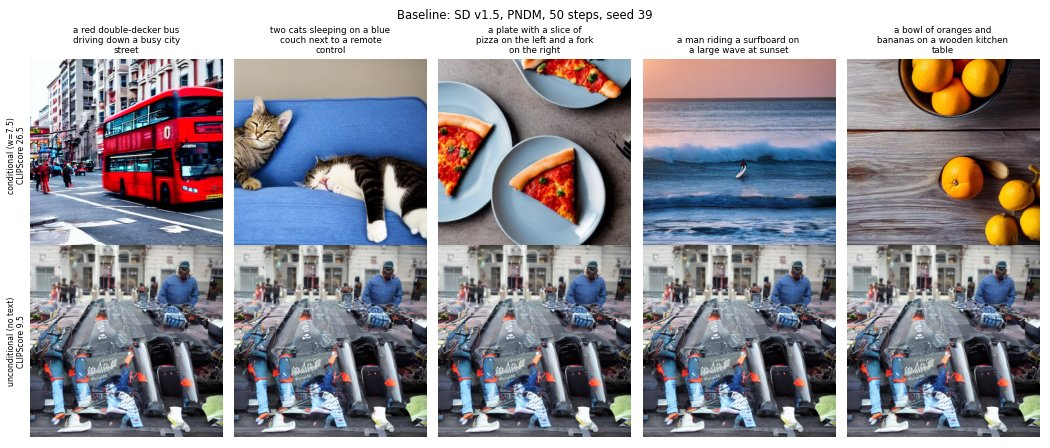

text conditioning adds +17.0 CLIPScore on average


In [9]:
g = save_grid([base_imgs, unc_imgs], PLOTS_DIR / "m2_baseline_cond_vs_uncond.jpg",
              row_labels=[f"conditional (w=7.5)\nCLIPScore {np.nanmean(base_scores):.1f}",
                          f"unconditional (no text)\nCLIPScore {np.nanmean(unc_scores):.1f}"],
              col_labels=prompts, title="Baseline: SD v1.5, PNDM, 50 steps, seed 39")
show(g, 1100)
print(f"text conditioning adds {np.nanmean(base_scores) - np.nanmean(unc_scores):+.1f} CLIPScore on average")

## 3. Tuning
### 3.1 Classifier free guidance scale `w`
We try different values of `w` with DPM++ 2M Karras, 25 steps and 2 seeds per prompt. We also track the mean HSV saturation, because a high `w` tends to make the colors too strong.

In [10]:
GUIDANCE_GRID = [1.0, 3.0, 5.0, 7.5, 10.0, 15.0]
CFG_SCHED, CFG_STEPS = "DPM++ 2M Karras", 25
CFG_SEEDS = [SEED, SEED + 1]

cfg_imgs = {}
for s in CFG_SEEDS:
    for w in GUIDANCE_GRID:
        imgs, dt, fl = generate(cond, uncond, s, CFG_SCHED, CFG_STEPS, w)
        record(imgs, prompts, s, SWEEP_DIR / "cfg_sweep", "cfg sweep", CFG_SCHED, CFG_STEPS, w, dt, fl, tag=f"w{w:g}_")
        cfg_imgs[(w, s)] = imgs
        print(f"seed {s}  w={w:<5g} {dt:4.1f}s/img")

cfg = pd.DataFrame(metrics).query("experiment == 'cfg sweep'")
cfg_summary = (cfg.groupby("guidance").agg(clip_mean=("clip_score", "mean"), clip_std=("clip_score", "std"),
                                           clip_n=("clip_score", "count"), saturation=("saturation", "mean"),
                                           runtime_s=("runtime_s", "mean"))
               .round(3).reset_index())
cfg_summary.to_csv(METRICS_DIR / "m2_cfg_sweep_summary.csv", index=False)
cfg_summary

seed 39  w=1      2.3s/img
seed 39  w=3      4.3s/img
seed 39  w=5      4.3s/img
seed 39  w=7.5    4.3s/img
seed 39  w=10     4.3s/img
seed 39  w=15     4.3s/img
seed 40  w=1      2.4s/img
seed 40  w=3      4.3s/img
seed 40  w=5      4.3s/img
seed 40  w=7.5    4.3s/img
seed 40  w=10     4.3s/img
seed 40  w=15     4.3s/img


,guidance,clip_mean,clip_std,clip_n,saturation,runtime_s
0,1.0,23.065,3.945,10,0.249,2.355
1,3.0,24.656,1.767,10,0.285,4.285
2,5.0,25.576,1.745,10,0.341,4.300
3,7.5,25.464,1.543,10,0.410,4.280
4,10.0,25.437,2.178,10,0.459,4.290
5,15.0,26.318,2.658,10,0.514,4.275


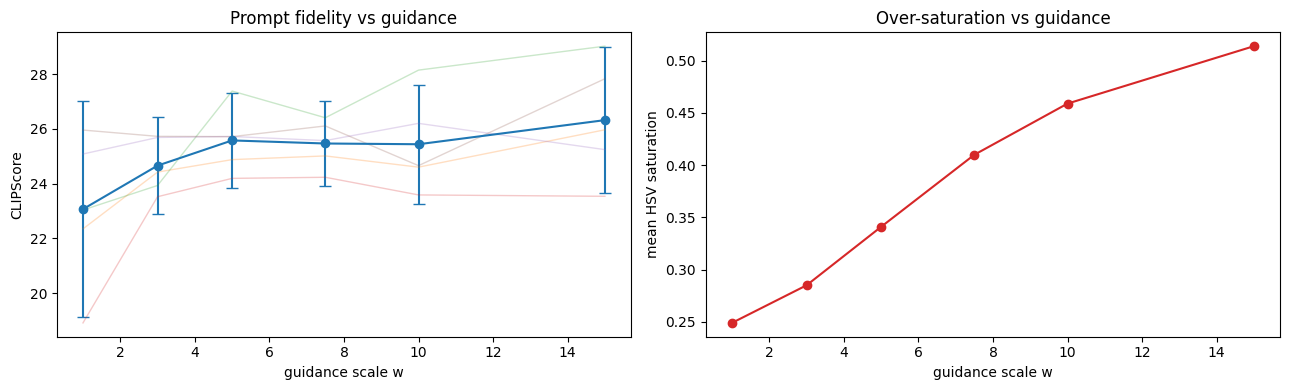

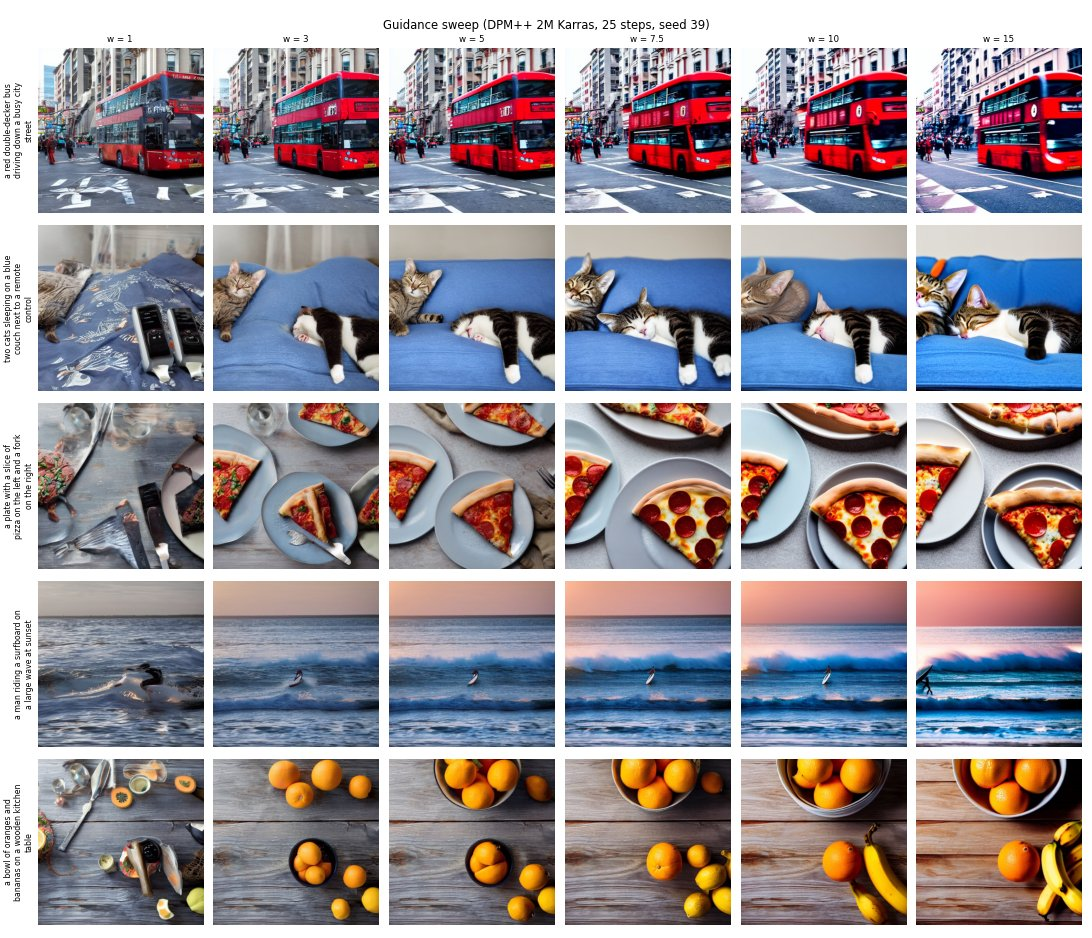

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].errorbar(cfg_summary.guidance, cfg_summary.clip_mean, yerr=cfg_summary.clip_std, marker="o", capsize=4)
for _, g_ in cfg.groupby("prompt_id"):
    ax[0].plot(*zip(*g_.groupby("guidance").clip_score.mean().items()), alpha=.25, lw=1)
ax[0].set(xlabel="guidance scale w", ylabel="CLIPScore", title="Prompt fidelity vs guidance")
ax[1].plot(cfg_summary.guidance, cfg_summary.saturation, marker="o", color="tab:red")
ax[1].set(xlabel="guidance scale w", ylabel="mean HSV saturation", title="Over-saturation vs guidance")
plt.tight_layout(); plt.savefig(PLOTS_DIR / "m2_cfg_sweep.png", dpi=110); plt.show()

g = save_grid([[cfg_imgs[(w, SEED)][i] for w in GUIDANCE_GRID] for i in range(len(prompts))],
              PLOTS_DIR / "m2_cfg_grid.jpg", row_labels=prompts, col_labels=[f"w = {w:g}" for w in GUIDANCE_GRID],
              cell=2.6, title=f"Guidance sweep ({CFG_SCHED}, {CFG_STEPS} steps, seed {SEED})")
show(g, 1100)

**Choosing `w`.** Each mean is based on 10 images, so differences smaller than one standard error (SE = std / √n) are just noise. We pick the **smallest `w` that is within one SE of the best score**. This way we avoid picking an oversaturated `w = 15` just by chance.

In [12]:
cfg_summary["clip_se"] = (cfg_summary.clip_std / np.sqrt(cfg_summary.clip_n)).round(3)
i_best = cfg_summary.clip_mean.idxmax()
threshold = cfg_summary.clip_mean[i_best] - cfg_summary.clip_se[i_best]
BEST_W = float(cfg_summary.loc[cfg_summary.clip_mean >= threshold, "guidance"].min())
chosen = cfg_summary.set_index("guidance").loc[BEST_W]
display(cfg_summary[["guidance", "clip_mean", "clip_se", "saturation"]])
print(f"best mean CLIPScore {cfg_summary.clip_mean[i_best]:.2f} at w={cfg_summary.guidance[i_best]:g} (SE {cfg_summary.clip_se[i_best]:.2f})"
      f" -> threshold {threshold:.2f} -> chosen w = {BEST_W:g} (CLIPScore {chosen.clip_mean:.2f}, saturation {chosen.saturation:.3f})")

,guidance,clip_mean,clip_se,saturation
0,1.0,23.065,1.248,0.249
1,3.0,24.656,0.559,0.285
2,5.0,25.576,0.552,0.341
3,7.5,25.464,0.488,0.410
4,10.0,25.437,0.689,0.459
5,15.0,26.318,0.841,0.514


best mean CLIPScore 26.32 at w=15 (SE 0.84) -> threshold 25.48 -> chosen w = 5 (CLIPScore 25.58, saturation 0.341)


### 3.2 Noise schedule
Stable Diffusion was trained with a fixed `scaled_linear` β schedule over 1000 steps. At inference time, we tune how the model moves through that schedule:
1. **Sampler**: DDPM (random), DDIM (a deterministic version of DDPM), PNDM (the SD default), Euler and DPM++ (ODE solvers), and Euler a (ancestral, which adds noise at every step).
2. **Sigma spacing**: the default spacing compared with Karras et al. (2022), which spends more steps at low noise levels.
3. **Number of steps**.

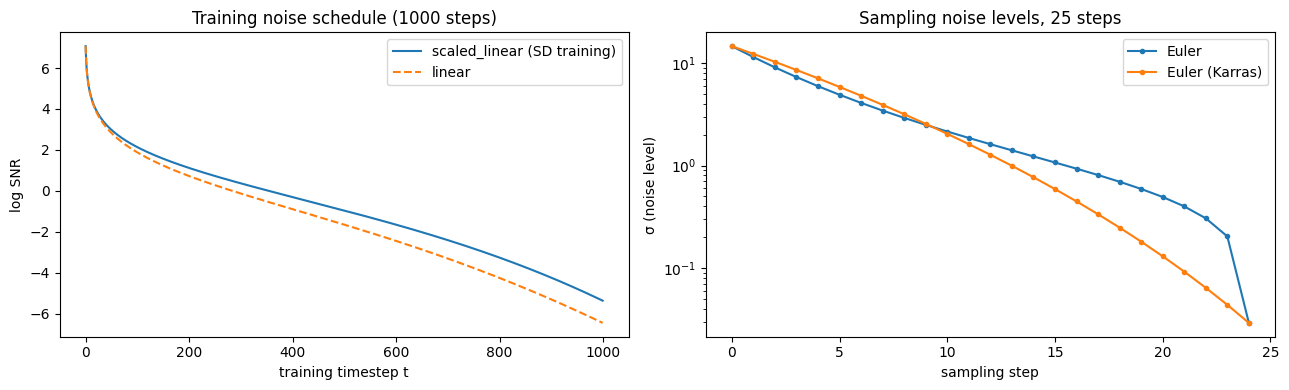

In [13]:
cfgS = pipe.scheduler.config
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for beta, ls in [("scaled_linear", "-"), ("linear", "--")]:
    ac = DDPMScheduler.from_config(cfgS, beta_schedule=beta).alphas_cumprod.numpy()
    ax[0].plot(np.log(ac / (1 - ac)), ls, label=beta + (" (SD training)" if beta == "scaled_linear" else ""))
ax[0].set(xlabel="training timestep t", ylabel="log SNR", title="Training noise schedule (1000 steps)"); ax[0].legend()

for name in ["Euler", "Euler (Karras)"]:
    s = SCHEDULERS[name](cfgS); s.set_timesteps(25)
    ax[1].plot(s.sigmas.numpy()[:-1], marker=".", label=name)
ax[1].set(xlabel="sampling step", ylabel="σ (noise level)", yscale="log", title="Sampling noise levels, 25 steps"); ax[1].legend()
plt.tight_layout(); plt.savefig(PLOTS_DIR / "m2_noise_schedules.png", dpi=110); plt.show()

In [14]:
SCHED_NAMES = list(SCHEDULERS)
STEPS_GRID = [10, 20, 30, 50]
SCHED_SEEDS = [SEED, SEED + 1]

sched_imgs = {}
for s in SCHED_SEEDS:
    for name in SCHED_NAMES:
        for n in STEPS_GRID:
            imgs, dt, fl = generate(cond, uncond, s, name, n, BEST_W)
            tag = name.lower().replace(" ", "").replace("+", "p").replace("(", "_").replace(")", "")
            cs = record(imgs, prompts, s, SWEEP_DIR / "scheduler_sweep", "scheduler sweep", name, n, BEST_W, dt, fl,
                        tag=f"{tag}_{n}steps_")
            if s == SEED:
                sched_imgs[(name, n)] = imgs
            print(f"seed {s}  {name:18s} {n:2d} steps  {dt:4.1f}s/img  CLIP {np.nanmean(cs):.2f}")

sch = pd.DataFrame(metrics).query("experiment == 'scheduler sweep'")
sched_summary = (sch.groupby(["scheduler", "steps"]).agg(clip_mean=("clip_score", "mean"), clip_std=("clip_score", "std"),
                                                         clip_n=("clip_score", "count"), runtime_s=("runtime_s", "mean"))
                 .round(3).reset_index())
sched_summary.to_csv(METRICS_DIR / "m2_scheduler_sweep_summary.csv", index=False)
sched_summary.pivot(index="scheduler", columns="steps", values="clip_mean").loc[SCHED_NAMES]

seed 39  PNDM (SD default)  10 steps   2.0s/img  CLIP 25.56
seed 39  PNDM (SD default)  20 steps   3.8s/img  CLIP 25.51
seed 39  PNDM (SD default)  30 steps   5.3s/img  CLIP 25.26
seed 39  PNDM (SD default)  50 steps   8.3s/img  CLIP 25.99
seed 39  DDIM               10 steps   1.9s/img  CLIP 25.09
seed 39  DDIM               20 steps   3.5s/img  CLIP 26.25
seed 39  DDIM               30 steps   5.1s/img  CLIP 25.91
seed 39  DDIM               50 steps   8.2s/img  CLIP 25.87
seed 39  DDPM               10 steps   1.9s/img  CLIP 25.49
seed 39  DDPM               20 steps   3.5s/img  CLIP 23.57
seed 39  DDPM               30 steps   5.1s/img  CLIP 26.18
seed 39  DDPM               50 steps   8.2s/img  CLIP 25.08
seed 39  Euler              10 steps   1.9s/img  CLIP 26.21
seed 39  Euler              20 steps   3.5s/img  CLIP 26.55
seed 39  Euler              30 steps   5.2s/img  CLIP 25.90
seed 39  Euler              50 steps   8.2s/img  CLIP 26.13
seed 39  Euler (Karras)     10 steps   1

steps,10,20,30,50
scheduler,,,,
PNDM (SD default),25.217,24.934,25.586,25.499
DDIM,25.275,25.420,25.217,25.525
DDPM,24.660,24.415,25.672,24.933
Euler,25.987,26.148,26.050,25.835
Euler (Karras),26.313,26.004,25.967,25.733
Euler a,25.029,24.910,26.359,25.944
DPM++ 2M,26.430,26.017,25.861,26.006
DPM++ 2M Karras,25.818,25.422,25.729,25.818


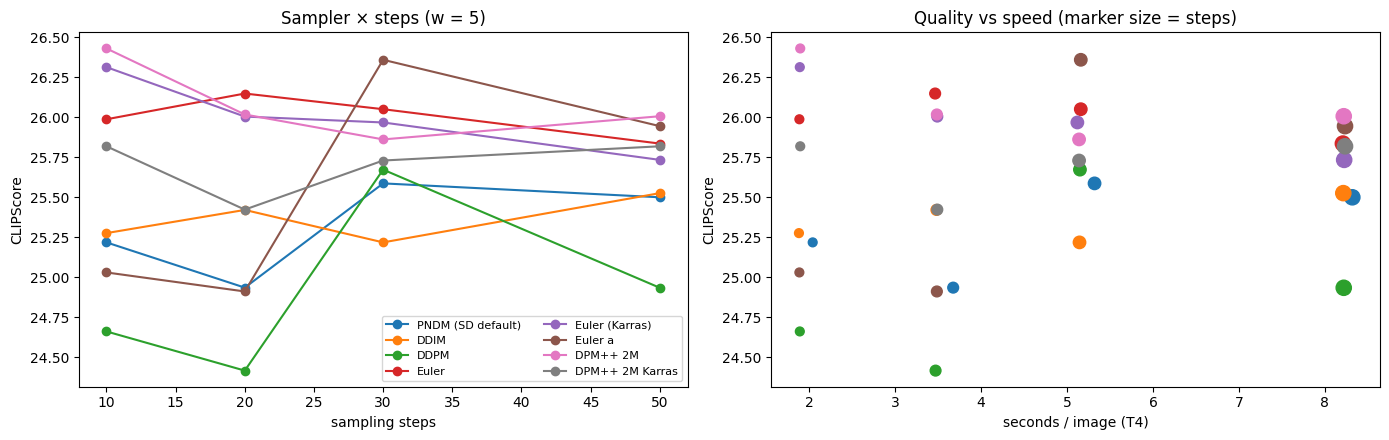

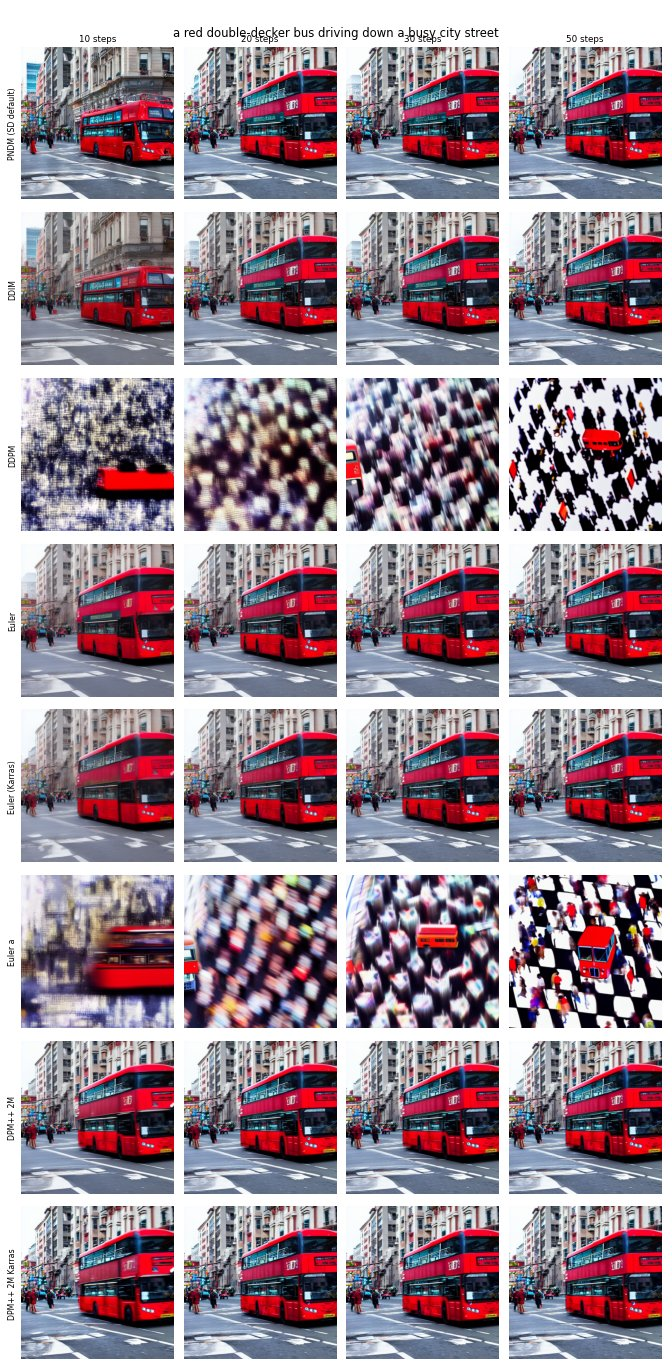

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name in SCHED_NAMES:
    d = sched_summary[sched_summary.scheduler == name]
    ax[0].plot(d.steps, d.clip_mean, marker="o", label=name)
    ax[1].scatter(d.runtime_s, d.clip_mean, s=20 + d.steps * 2, label=name)
ax[0].set(xlabel="sampling steps", ylabel="CLIPScore", title=f"Sampler × steps (w = {BEST_W:g})")
ax[1].set(xlabel="seconds / image (T4)", ylabel="CLIPScore", title="Quality vs speed (marker size = steps)")
ax[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig(PLOTS_DIR / "m2_scheduler_sweep.png", dpi=110); plt.show()

for i, p in enumerate(prompts):
    save_grid([[sched_imgs[(nm, n)][i] for n in STEPS_GRID] for nm in SCHED_NAMES],
              PLOTS_DIR / f"m2_scheduler_grid_p{i+1:02d}.jpg", row_labels=SCHED_NAMES,
              col_labels=[f"{n} steps" for n in STEPS_GRID], cell=2.4, title=p)
show(PLOTS_DIR / "m2_scheduler_grid_p01.jpg", 700)

**Choosing the sampler.** We only consider **deterministic** samplers with **at least 20 steps**. DDPM and Euler a add noise at every step, which leaves some blur that CLIPScore barely notices. Setups with only 10 steps can also score about the same on CLIPScore while looking worse. From the setups within one SE of the best score, we pick the fastest one.

In [16]:
MIN_STEPS = 20
STOCHASTIC = {"DDPM", "Euler a"}
sched_summary["clip_se"] = (sched_summary.clip_std / np.sqrt(sched_summary.clip_n)).round(3)
eligible = sched_summary[(sched_summary.steps >= MIN_STEPS) & ~sched_summary.scheduler.isin(STOCHASTIC)]
i_best = eligible.clip_mean.idxmax()
best_sched_clip = eligible.clip_mean[i_best]
near = (eligible[eligible.clip_mean >= best_sched_clip - eligible.clip_se[i_best]]
        .sort_values(["runtime_s", "clip_mean"], ascending=[True, False]))
BEST = dict(scheduler=near.iloc[0].scheduler, steps=int(near.iloc[0].steps), guidance=BEST_W)
print(f"deterministic configs with >= {MIN_STEPS} steps within one SE of the best ({best_sched_clip:.2f} ± {eligible.clip_se[i_best]:.2f}):")
display(near)
print("chosen config:", BEST)

deterministic configs with >= 20 steps within one SE of the best (26.15 ± 0.77):


,scheduler,steps,clip_mean,clip_std,clip_n,runtime_s,clip_se
17,Euler,20,26.148,2.430,10,3.465,0.768
1,DDIM,20,25.420,2.470,9,3.480,0.823
9,DPM++ 2M,20,26.017,2.593,10,3.485,0.820
21,Euler (Karras),20,26.004,2.487,10,3.490,0.786
13,DPM++ 2M Karras,20,25.422,1.684,10,3.490,0.533
22,Euler (Karras),30,25.967,2.403,10,5.120,0.760
10,DPM++ 2M,30,25.861,2.000,10,5.140,0.632
14,DPM++ 2M Karras,30,25.729,1.596,10,5.140,0.505
18,Euler,30,26.050,2.421,10,5.160,0.766
30,PNDM (SD default),30,25.586,2.545,10,5.320,0.805


chosen config: {'scheduler': 'Euler', 'steps': 20, 'guidance': 5.0}


## 4. First set of generated images (tuned setup)
We generate the 5 test prompts with seeds 39 to 42 using the tuned setup. Then we generate images for 10 COCO test captions that we kept aside, and show them next to their real photos.

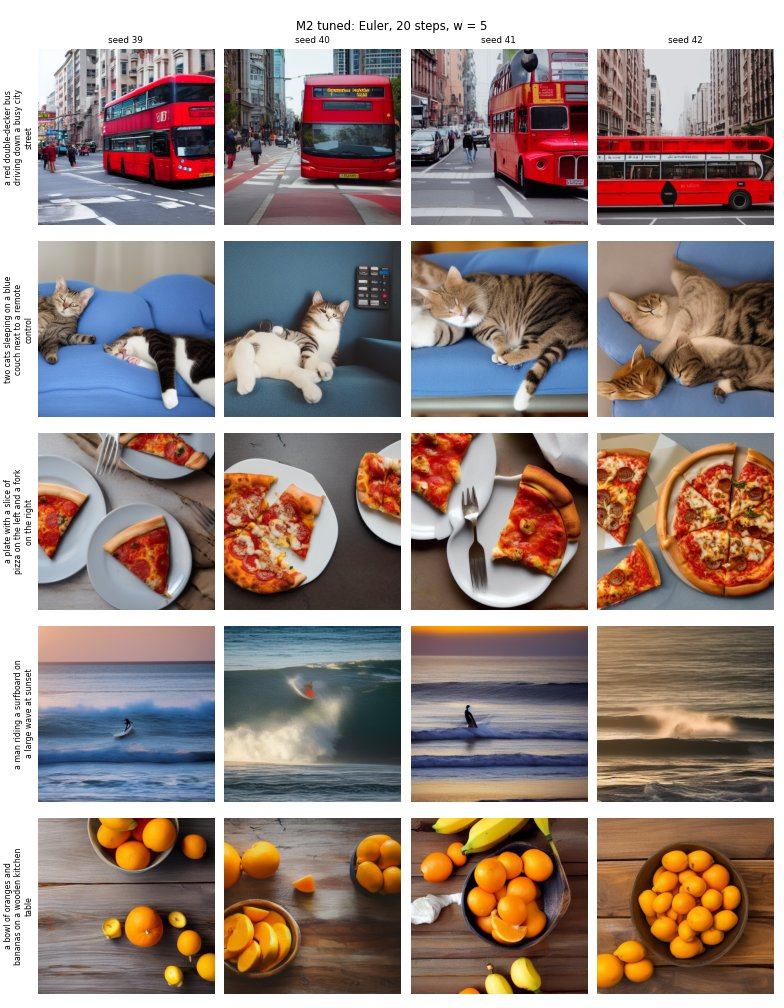

In [17]:
final = {}
for s in EVAL_SEEDS:
    imgs, dt, fl = generate(cond, uncond, s, **BEST)
    record(imgs, prompts, s, SAMPLES_DIR / "final_set", "final set (tuned)", **BEST, runtime_s=dt, flags=fl,
           notes="M2 tuned config")
    final[s] = imgs

g = save_grid([[final[s][i] for s in EVAL_SEEDS] for i in range(len(prompts))],
              SAMPLES_DIR / "final_set" / "grid.jpg", row_labels=prompts,
              col_labels=[f"seed {s}" for s in EVAL_SEEDS], cell=2.8,
              title=f"M2 tuned: {BEST['scheduler']}, {BEST['steps']} steps, w = {BEST['guidance']:g}")
show(g, 900)

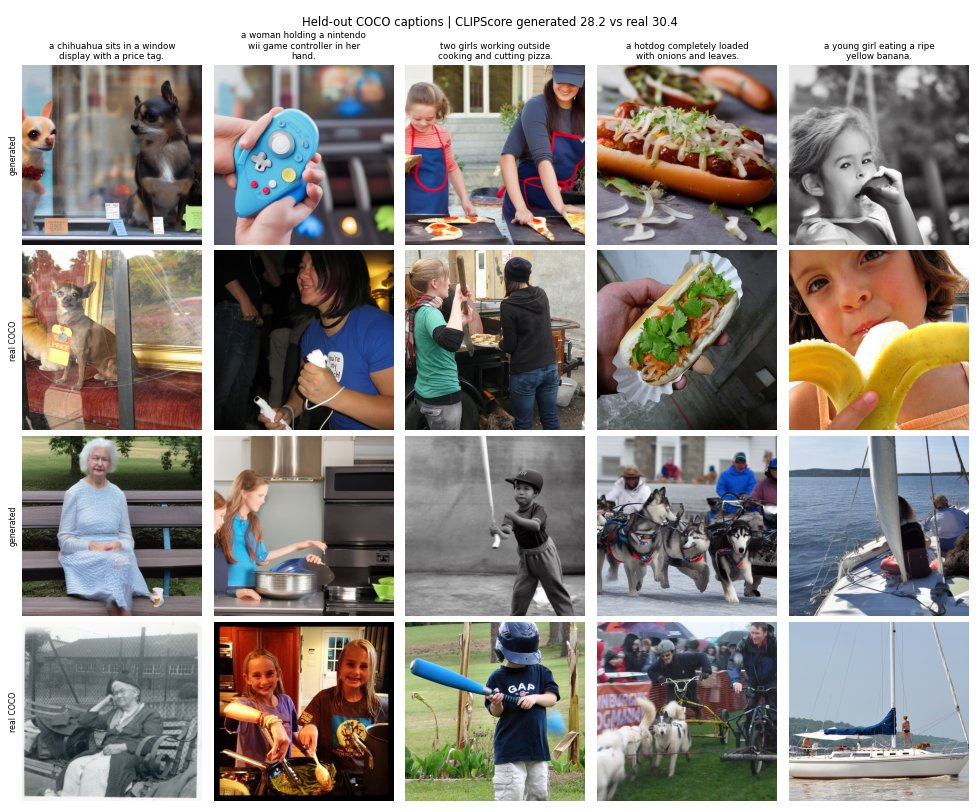

,image_id,caption,clip_generated,clip_real
0,355240,a chihuahua sits in a window display with a pr...,34.08,41.84
1,318138,a woman holding a nintendo wii game controller...,22.31,31.02
2,161925,two girls working outside cooking and cutting ...,27.78,25.66
3,118367,a hotdog completely loaded with onions and lea...,24.72,26.16
4,550714,a young girl eating a ripe yellow banana.,25.75,28.56
5,273132,older woman in dress sitting on a park bench.,33.33,29.27
6,512929,two preteens standing at the stove cooking gre...,28.02,29.39
7,370375,a young boy swings a plastic bat while wearing...,27.85,31.84
8,107226,men race on wheeled vehicles towed by a group ...,30.98,32.79
9,286422,two people and a dog are on a sailboat.,26.83,26.99


In [18]:
pairs = pd.read_csv(PROC_DIR / "pairs_clean.csv")
pairs["image_path"] = pairs.file_name.map(lambda f: str(PROC_DIR / "images" / f))
coco = pairs[pairs.split == "test"].sample(10, random_state=SEED).reset_index(drop=True)
captions = coco.caption.tolist()

c_cond = encode_text(captions)
coco_imgs, coco_fl, dts = [], [], []
for k in range(0, len(coco), 5):
    im, dt, fl = generate(c_cond[k:k + 5], uncond, SEED, **BEST)
    coco_imgs += im; coco_fl += fl; dts.append(dt)
gen_cs = record(coco_imgs, captions, SEED, SAMPLES_DIR / "coco_test", "coco test (tuned)", **BEST,
                runtime_s=float(np.mean(dts)), flags=coco_fl, tag="coco_", notes="held-out COCO test-split caption")
real_cs = clip_score(coco.image_path.tolist(), captions)
coco_res = coco[["image_id", "caption"]].assign(clip_generated=gen_cs, clip_real=real_cs)
coco_res.to_csv(METRICS_DIR / "m2_coco_test_clipscore.csv", index=False)

real = [Image.open(p).convert("RGB") for p in coco.image_path]
g = save_grid([coco_imgs[:5], real[:5], coco_imgs[5:], real[5:]], PLOTS_DIR / "m2_coco_generated_vs_real.jpg",
              row_labels=["generated", "real COCO", "generated", "real COCO"], col_labels=captions[:5], cell=2.8,
              title=f"Held-out COCO captions | CLIPScore generated {np.nanmean(gen_cs):.1f} vs real {np.mean(real_cs):.1f}")
show(g, 1000)
coco_res

### 4.1 Baseline vs tuned
Both setups are scored on the same prompts and seeds. Seeds 41 and 42 were not used during tuning, so we also report them on their own as an extra check on unseen seeds.

,config,clip_mean,clip_se,clip_heldout,saturation,sec_per_img,speedup
M1/M2 baseline,"PNDM (SD default), 50 steps, w=7.5",25.935,0.426,25.512,0.429,8.415,1.00
M2 tuned,"Euler, 20 steps, w=5",25.988,0.494,25.829,0.391,3.538,2.38


held-out seeds (not used for tuning): [41, 42]


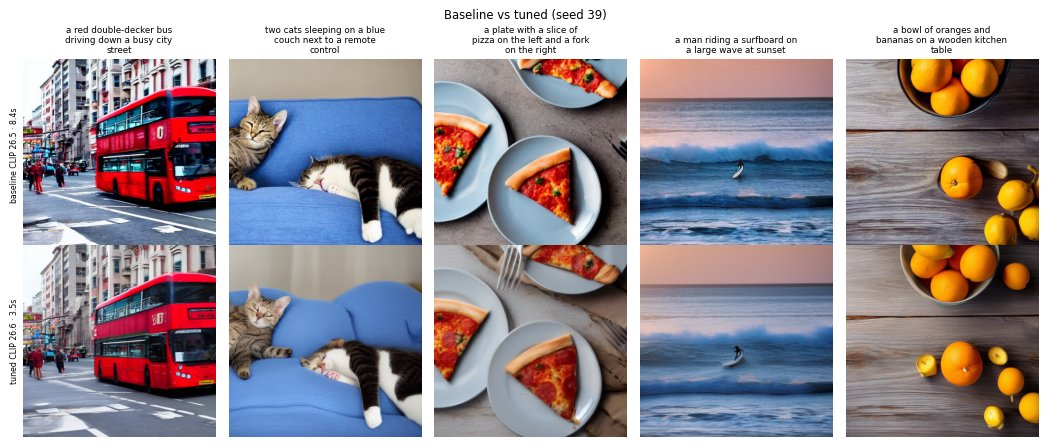

441 rows appended to results/logs/generation_log.csv this session | 441 images scored


In [19]:
m = pd.DataFrame(metrics)
m.to_csv(METRICS_DIR / "m2_all_generations.csv", index=False)

HELDOUT = [s for s in EVAL_SEEDS if s not in CFG_SEEDS + SCHED_SEEDS]
b = m[m.experiment == "baseline (conditional)"]
t = m[m.experiment == "final set (tuned)"]
summary = pd.DataFrame({
    "config":       [f"{BASE['scheduler']}, {BASE['steps']} steps, w={BASE['guidance']:g}",
                     f"{BEST['scheduler']}, {BEST['steps']} steps, w={BEST['guidance']:g}"],
    "clip_mean":    [b.clip_score.mean(), t.clip_score.mean()],
    "clip_se":      [b.clip_score.std() / np.sqrt(b.clip_score.count()), t.clip_score.std() / np.sqrt(t.clip_score.count())],
    "clip_heldout": [b[b.seed.isin(HELDOUT)].clip_score.mean(), t[t.seed.isin(HELDOUT)].clip_score.mean()],
    "saturation":   [b.saturation.mean(), t.saturation.mean()],
    "sec_per_img":  [b.runtime_s.mean(), t.runtime_s.mean()],
}, index=["M1/M2 baseline", "M2 tuned"]).round(3)
summary["speedup"] = (summary.sec_per_img.iloc[0] / summary.sec_per_img).round(2)
display(summary)
print(f"held-out seeds (not used for tuning): {HELDOUT}")

b39, t39 = b[b.seed == SEED], t[t.seed == SEED]
g = save_grid([base_imgs, final[SEED]], PLOTS_DIR / "m2_baseline_vs_tuned.jpg",
              row_labels=[f"baseline\nCLIP {b39.clip_score.mean():.1f} · {b.runtime_s.mean():.1f}s",
                          f"tuned\nCLIP {t39.clip_score.mean():.1f} · {t.runtime_s.mean():.1f}s"],
              col_labels=prompts, title="Baseline vs tuned (seed 39)")
show(g, 1100)

report = {
    "baseline": BASE, "tuned": BEST, "eval_seeds": EVAL_SEEDS, "heldout_seeds": HELDOUT,
    "cfg_sweep": cfg_summary.to_dict("records"),
    "baseline_vs_tuned": summary.reset_index().to_dict("records"),
    "unconditional_clip_mean": round(float(np.nanmean(unc_scores)), 3),
    "coco_test_clip": {"generated": round(float(np.nanmean(gen_cs)), 3), "real": round(float(np.mean(real_cs)), 3)},
    "n_images_generated": len(m),
}
(METRICS_DIR / "m2_summary.json").write_text(json.dumps(report, indent=2, default=str))
print(f"{len(m)} rows appended to {LOG_CSV.relative_to(REPO_DIR)} this session | {len(m)} images scored")

## 5. Download results
Colab deletes its copy of the repo when the session ends. Download the zip and copy `results/` into your local repo before committing.

In [20]:
from google.colab import files
bundle = Path("/content/m2_results")
if bundle.exists():
    shutil.rmtree(bundle)
shutil.copytree(RESULTS_DIR, bundle / "results")
shutil.make_archive("/content/m2_results", "zip", bundle)
print(f"{sum(1 for f in (bundle / 'results').rglob('*') if f.is_file())} files")
files.download("/content/m2_results.zip")

94 files
